# T09 · Robustesse, attaques & gouvernance des modèles — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- **Mesurer** la robustesse d'un détecteur cyber (MLP numpy) : bruit d'entrée, variance entre graines, attaques adaptatives FGSM
- **Détecter et corriger** les failles propres aux modèles appriss : biais de catégorie, dérive temporelle, empoisonnement d'étiquettes
- **Gouverner** le déploiement : scorecard de robustesse, seuils d'alerte, humain dans la boucle (réf. EU AI Act — vue pratique)

Pourquoi c'est fondamental en cyber :

| Besoin cyber | Outil (point du cours) |
|---|---|
| Un faux négatif = une brèche invisible | Rappel par classe + scorecard robustesse (P2, P7) |
| Savoir si le modèle tient face à un attaquant malin | Attaque FGSM mesurée en boîte blanche (P4) |
| Les techniques de phishing évoluent chaque semaine | Suivi de dérive temporelle + re-entraînement (P2) |
| Un jeu de données trafiqué = détecteur aveugle | Impact d'empoisonnement des étiquettes mesuré (P3) |
| Pas de boîte noire totale en production | Score de confiance + file d'analyse humaine (P5, P6) |

**Prérequis :** T01 (MLP numpy, rétropropagation), T03 (régularisation, optimiseurs), T06 (erreur de reconstruction, score d'anomalie). Matrice de confusion, rappel et AUC acquis.

> **Conseil d'étude :** refaites chaque exercice Pn sans regarder, puis dites à voix haute ce que la valeur assertée dit du *risque cyber*. Un modèle non robusté n'est pas un modèle inachevé — c'est une porte dérobée clé en main pour l'attaquant.

## 📌 Bloc 0 — Environnement & imports

Tout est calculé **en numpy pur** : le MLP, sa backpropagation et l'attaque FGSM sont écrits à la main. Aucun framework deep learning — l'objectif est de comprendre les mécanismes de gradient qu'un attaquant exploite exactement comme l'entraînement les exploite.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score

np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · Robustesse & stabilité : sensibilité au bruit, variance entre graines

Un détecteur robuste conserve ses performances sous de petites perturbations de l'entrée. Deux aléas à séparer :

- **Aléa d'observation** — le même modèle voit ses performances se dégrader quand l'entrée est bruitée. On mesure une **courbe de dégradation** exactitude = f(σ).
- **Aléa d'apprentissage** — deux graines différentes donnent deux modèles différents. On rapporte l'**écart-type d'exactitude entre graines**, jamais un nombre unique.

**Garantie géométrique (modèle linéaire).** Sous une perturbation δ avec ‖δ‖∞ ≤ ε, le logit w·x ne bouge que de |δ·w| ≤ ε·‖w‖₁ (inégalité de Hölder). Donc si la **marge** |w·x| dépasse ε·‖w‖₁, la décision ne peut pas basculer : c'est une *certification* gratuite en L∞.

| Ce qu'on mesure | Formule | Lecture cyber |
|---|---|---|
| Dégradation sous bruit | acc(x + N(0, σ²I)) | capteur/telemetry bruité |
| Stabilité inter-graines | std(acc) sur k graines | reproductibilité des chiffres audités |
| Certificat L∞ (linéaire) | marge > ε·‖w‖₁ | inversions impossibles ⇒ risque borné |

**Piège classique :** annoncer « 98,9 % d'exactitude » avec *une seule* graine est un mirage marketing — sans l'écart-type entre graines, le chiffre ne vaut rien en revue d'architecture.

In [2]:
# ---- Boite a outils du notebook : MLP numpy + donnees URL synthetiques ----
# Pure-numpy MLP: hidden tanh layers + sigmoid output, BCE loss, Adam.
# Manual forward/backward; also exposes gradients w.r.t. inputs (used by FGSM/PGD).
class MLP:
    '''Dense net with tanh hidden layers and a sigmoid output (binary BCE).'''

    def __init__(self, dims, seed=0, lr=0.01):
        rng = np.random.default_rng(seed)
        self.dims, self.lr = dims, lr
        self.W, self.b = [], []
        for i in range(len(dims) - 1):
            limit = np.sqrt(6.0 / (dims[i] + dims[i + 1]))  # Xavier init
            self.W.append(rng.uniform(-limit, limit, (dims[i], dims[i + 1])))
            self.b.append(np.zeros(dims[i + 1]))

    def forward(self, X):
        self.a, self.z = [X], []
        h, n = X, len(self.W)
        for i in range(n):
            z = h @ self.W[i] + self.b[i]
            h = np.tanh(z) if i < n - 1 else 1.0 / (1.0 + np.exp(-np.clip(z, -30, 30)))
            self.z.append(z); self.a.append(h)
        return self.a[-1][:, 0]

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        return (self.forward(X) >= 0.5).astype(int)

    def loss(self, X, y):
        p = np.clip(self.forward(X), 1e-12, 1 - 1e-12)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def grad_input(self, X, y):
        # d(BCE)/dX through the whole net — exactly the quantity an attacker needs.
        p = self.forward(X)
        m, n = X.shape[0], len(self.W)
        delta = (p - y)[:, None] / m
        for i in range(n - 1, 0, -1):
            delta = (delta @ self.W[i].T) * (1.0 - self.a[i] ** 2)
        return delta @ self.W[0].T

    def _pgd(self, Xb, yb, eps, steps):
        # PGD inside the L-inf ball, clipped to the legal feature range [0, 1].
        alpha = 1.5 * eps / max(steps, 1)
        Xa = Xb.copy()
        for _ in range(steps):
            g = self.grad_input(Xa, yb)
            Xa = np.clip(Xa + alpha * np.sign(g), Xb - eps, Xb + eps)
            Xa = np.clip(Xa, 0.0, 1.0)
        return Xa

    def train(self, X, y, epochs=150, batch=64, lr=None, seed=0, adv_eps=0.0, adv_steps=1):
        # Mini-batch Adam. If adv_eps > 0, every batch mixes clean + PGD examples.
        rng = np.random.default_rng(seed)
        lr = self.lr if lr is None else lr
        n = len(self.W)
        mW = [np.zeros_like(w) for w in self.W]; vW = [np.zeros_like(w) for w in self.W]
        mb = [np.zeros_like(bb) for bb in self.b]; vb = [np.zeros_like(bb) for bb in self.b]
        t, N = 0, X.shape[0]
        for _ in range(epochs):
            perm = rng.permutation(N)
            for s in range(0, N, batch):
                idx = perm[s:s + batch]
                Xb, yb = X[idx], y[idx]
                if adv_eps > 0:
                    if adv_steps == 1:
                        Xadv = np.clip(Xb + adv_eps * np.sign(self.grad_input(Xb, yb)), 0.0, 1.0)
                    else:
                        Xadv = self._pgd(Xb, yb, adv_eps, adv_steps)
                    Xb = np.vstack([Xb, Xadv]); yb = np.r_[yb, yb]
                p = self.forward(Xb)
                m_ = Xb.shape[0]
                delta = (p - yb)[:, None] / m_
                t += 1
                for i in range(n - 1, -1, -1):
                    gW = self.a[i].T @ delta
                    gb = delta.sum(axis=0)
                    if i > 0:
                        delta = (delta @ self.W[i].T) * (1.0 - self.a[i] ** 2)
                    gW = np.clip(gW, -5, 5); gb = np.clip(gb, -5, 5)  # gradient clipping
                    mW[i] = 0.9 * mW[i] + 0.1 * gW
                    vW[i] = 0.999 * vW[i] + 0.001 * gW ** 2
                    mb[i] = 0.9 * mb[i] + 0.1 * gb
                    vb[i] = 0.999 * vb[i] + 0.001 * gb ** 2
                    self.W[i] -= lr * (mW[i] / (1 - 0.9 ** t)) / (np.sqrt(vW[i] / (1 - 0.999 ** t)) + 1e-8)
                    self.b[i] -= lr * (mb[i] / (1 - 0.9 ** t)) / (np.sqrt(vb[i] / (1 - 0.999 ** t)) + 1e-8)
        return self


def accuracy(model, X, y):
    return float(np.mean(model.predict(X) == y))


# Synthetic URL features (all scores normalised in [0, 1]) — phishing vs legit.
FEATURES = ["longueur_url", "ratio_chiffres", "https", "adresse_ip",
            "age_domaine", "formulaire_login", "entropie_caracteres", "tld_suspect"]
MU_LEGIT = np.array([0.30, 0.25, 0.70, 0.15, 0.65, 0.25, 0.35, 0.20])
MU_PHISH = np.array([0.65, 0.60, 0.35, 0.50, 0.30, 0.60, 0.70, 0.55])
SIGMA = 0.22


def make_url_data(n_legit, n_phish, seed=0, phish_shift=0.0):
    # phish_shift slides the phishing centroid toward the legit one (drift).
    rng = np.random.default_rng(seed)

    def draw(mu, n):
        return np.clip(rng.normal(mu, SIGMA, (n, len(MU_LEGIT))), 0.0, 1.0)

    X = np.vstack([draw(MU_LEGIT, n_legit), draw(MU_PHISH - phish_shift, n_phish)])
    y = np.r_[np.zeros(n_legit), np.ones(n_phish)]
    perm = rng.permutation(len(y))
    return X[perm], y[perm]


def split(X, y, frac=0.7):
    k = int(frac * len(y))
    return X[:k], X[k:], y[:k], y[k:]


print("Boite a outils prete : MLP numpy (", len(FEATURES), "entrees, 1 couche cachee de 16, sortie sigmoid ).")

Boite a outils prete : MLP numpy ( 8 entrees, 1 couche cachee de 16, sortie sigmoid ).


Exactitude de base (test propre) = 0.9889
  bruit sigma = 0.00  ->  exactitude = 0.9889
  bruit sigma = 0.05  ->  exactitude = 0.9861
  bruit sigma = 0.10  ->  exactitude = 0.9944
  bruit sigma = 0.15  ->  exactitude = 0.9694
  bruit sigma = 0.20  ->  exactitude = 0.9528
  bruit sigma = 0.30  ->  exactitude = 0.8861


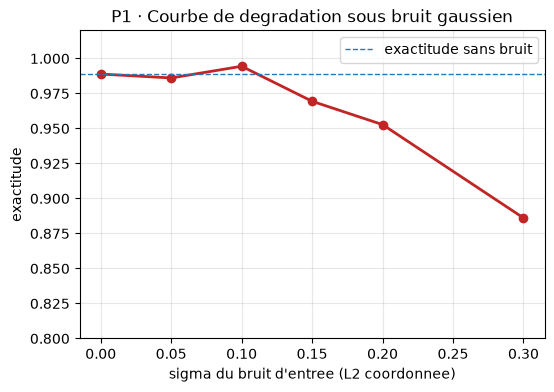

In [3]:
# Baseline detector + degradation curve under input noise
Xtr, Xte, ytr, yte = split(*make_url_data(600, 600, seed=1))
base = MLP([8, 16, 1], seed=42).train(Xtr, ytr, epochs=150, seed=42)
acc_base = accuracy(base, Xte, yte)
print(f"Exactitude de base (test propre) = {acc_base:.4f}")

rng = np.random.default_rng(11)  # cell-local stream
noise_curve = []
for s in [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]:
    Xn = Xte if s == 0 else np.clip(Xte + rng.normal(0, s, Xte.shape), 0, 1)
    noise_curve.append((s, accuracy(base, Xn, yte)))
    print(f"  bruit sigma = {s:.2f}  ->  exactitude = {noise_curve[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([s for s, _ in noise_curve], [a for _, a in noise_curve], "o-",
        color="#c12526", lw=2)
ax.axhline(acc_base, color="#2878b5", ls="--", lw=1, label="exactitude sans bruit")
ax.set_xlabel("sigma du bruit d'entree (L2 coordonnee)"); ax.set_ylabel("exactitude")
ax.set_title("P1 · Courbe de degradation sous bruit gaussien")
ax.set_ylim(0.8, 1.02); ax.legend(); ax.grid(alpha=0.3)
plt.show()

assert acc_base > 0.95
assert noise_curve[-1][1] < acc_base - 0.05          # visible degradation at sigma=0.30
assert noise_curve[-1][1] > 0.85                     # graceful, not catastrophic

In [4]:
# Accuracy variance across random seeds (same data, different init + shuffling)
accs = [accuracy(MLP([8, 16, 1], seed=100 + s).train(Xtr, ytr, epochs=150, seed=200 + s),
                 Xte, yte) for s in range(8)]
seed_std = float(np.std(accs))
print("Exactitudes par graine :", np.round(accs, 4))
print(f"Moyenne = {np.mean(accs):.4f}   ecart-type inter-graines = {seed_std:.4f}")
print("-> un audit n'annonce JAMAIS la moyenne sans l'ecart-type.")

assert 0.0005 < seed_std < 0.01                      # probed: 0.00196
assert abs(float(np.mean(accs)) - 0.990) < 0.01

Exactitudes par graine : [0.989 0.986 0.992 0.992 0.989 0.992 0.992 0.992]
Moyenne = 0.9903   ecart-type inter-graines = 0.0020
-> un audit n'annonce JAMAIS la moyenne sans l'ecart-type.


### Exercice corrigé

À refaire sans regarder : certificats L∞ d'un modèle linéaire à coefficients connus, et écart-type calculé à la main.

In [5]:
# ---- Exercice P1 : boule L-inf, certificat de marge et std entre graines ----
# Linear score s(x) = w.x ; perturbation delta with ||delta||_inf <= eps.
# Holder: |delta.w| <= eps * ||w||_1  ->  decision cannot flip if margin > eps*||w||_1.
w1 = np.array([2.0, -1.0, 0.5])
eps1, marge1 = 0.5, 2.0

norme_l1 = np.abs(w1).sum()                    # hand: 2 + 1 + 0.5
assert np.isclose(norme_l1, 3.5)
assert np.isclose(eps1 * norme_l1, 1.75)       # worst-case logit shift
assert bool(eps1 * norme_l1 < marge1)          # margin 2.0 > 1.75 -> flip impossible
marge2 = 1.5                                   # margin 1.5 < 1.75 -> flip NOT excluded
assert bool(eps1 * norme_l1 > marge2)

# Seed std by hand on two runs: [0.88, 0.92] -> mean 0.90, std 0.02
accs2 = np.array([0.88, 0.92])
assert np.isclose(accs2.mean(), 0.90)
assert np.isclose(accs2.std(), 0.02)
print("P1 verifie : ||w||1 = 3.5, deplacement max du logit = 1.75 < marge 2.0 (sur).")
print("P1 verifie : std inter-graines [0.88, 0.92] = 0.02.")

P1 verifie : ||w||1 = 3.5, deplacement max du logit = 1.75 < marge 2.0 (sur).
P1 verifie : std inter-graines [0.88, 0.92] = 0.02.


## 2 · Biais & dérives des modèles IA : catégories sous-détectées, dérive temporelle

**Biais de catégorie.** En cybersécurité la classe d'intérêt est *rare* (le phishing est ~4 % du trafic). Un détecteur qui dirait toujours « légitime » afficherait ~95 % d'exactitude ! L'exactitude globale masque l'effondrement du **rappel de la classe minoritaire** — celle qui compte. On impose un *gap de rappel* maximal entre classes.

**Dérive temporelle (drift).** Les campagnes de phishing évoluent (nouveaux TLD, URLs raccourcies…) : les caractéristiques dérivent semaine après semaine. Un modèle figé voit son exactitude décroître. Correctif : **surveiller la dérive et re-entraîner** sur les données récentes.

**Piège classique :** ne monitorer que l'exactitude globale → la classe minoritaire peut s'effondrer sans que le tableau de bord bronche. Toujours : rappel par classe + prévalence.

In [6]:
# Imbalanced detector: 4% phishing — per-class recall exposes the blind spot
Xi, yi = make_url_data(1152, 48, seed=2, phish_shift=0.18)   # 4% minority
Xtri, Xtei, ytri, ytei = split(Xi, yi)
imb = MLP([8, 16, 1], seed=7).train(Xtri, ytri, epochs=150, seed=7)
pred_i = imb.predict(Xtei)
acc_i = float(np.mean(pred_i == ytei))
rec_min = float(np.mean(pred_i[ytei == 1] == 1))   # phishing = minority
rec_maj = float(np.mean(pred_i[ytei == 0] == 0))   # legit = majority
always_majority = float(np.mean(ytei == 0))        # acc of a trivial 'always legit' rule
print(f"Exactitude globale = {acc_i:.4f}   (le classifieur 'toujours legitime' fait deja {always_majority:.4f} !)")
print(f"Rappel phishing (minoritaire) = {rec_min:.4f}   Rappel legitime = {rec_maj:.4f}")
print(f"-> gap de rappel = {rec_maj - rec_min:.4f} : la classe qui compte est sous-detectee.")

assert rec_maj > rec_min + 0.10                    # probed gap: 0.174
assert rec_maj > 0.95
assert always_majority > 0.90                      # the accuracy paradox, measured
assert acc_i > 0.95

Exactitude globale = 0.9889   (le classifieur 'toujours legitime' fait deja 0.9528 !)
Rappel phishing (minoritaire) = 0.8235   Rappel legitime = 0.9971
-> gap de rappel = 0.1736 : la classe qui compte est sous-detectee.


In [7]:
# Temporal drift: phishing features slide toward legit week after week
week_accs = []
for w in range(5):
    _, Xew, _, yew = split(*make_url_data(600, 600, seed=3, phish_shift=0.06 * w))
    week_accs.append(accuracy(base, Xew, yew))
    print(f"  semaine {w}  (glissement {0.06 * w:.2f})  ->  exactitude = {week_accs[-1]:.4f}")

assert all(week_accs[i + 1] < week_accs[i] for i in range(4))   # monotone decay
assert week_accs[4] < week_accs[0] - 0.10

# Retrain on week-4 data -> recovery
Xtr4, Xte4, ytr4, yte4 = split(*make_url_data(600, 600, seed=3, phish_shift=0.24))
retr = MLP([8, 16, 1], seed=9).train(Xtr4, ytr4, epochs=150, seed=9)
acc_retr = accuracy(retr, Xte4, yte4)
print(f"Re-entrainement sur les donnees de la semaine 4 -> exactitude = {acc_retr:.4f}")
print("-> la derive est corrigee par re-entrainement recent (procedures MLOps).")

assert acc_retr > 0.95
assert acc_retr > week_accs[4] + 0.10

  semaine 0  (glissement 0.00)  ->  exactitude = 0.9889
  semaine 1  (glissement 0.06)  ->  exactitude = 0.9750
  semaine 2  (glissement 0.12)  ->  exactitude = 0.9500
  semaine 3  (glissement 0.18)  ->  exactitude = 0.8972
  semaine 4  (glissement 0.24)  ->  exactitude = 0.8361
Re-entrainement sur les donnees de la semaine 4 -> exactitude = 0.9778
-> la derive est corrigee par re-entrainement recent (procedures MLOps).


### Exercice corrigé

Matrice de confusion donnée à la main : calculer rappels, gap et exactitude — et voir pourquoi l'exactitude est trompeuse.

In [8]:
# ---- Exercice P2 : rappels par classe sur matrice de confusion connue ----
# Confusion (phishing = positive class): TP=90, FN=10, FP=5, TN=895
TP, FN, FP, TN = 90, 10, 5, 895
n_pos, n_neg = TP + FN, TN + FP                      # 100 phishing, 900 legit
assert n_pos + n_neg == 1000

rappel_pos = TP / n_pos                               # hand: 90/100
rappel_neg = TN / n_neg                               # hand: 895/900
exactitude = (TP + TN) / (n_pos + n_neg)              # hand: 985/1000
gap = rappel_neg - rappel_pos

assert np.isclose(rappel_pos, 0.90)
assert np.isclose(rappel_neg, 895 / 900)              # 0.99444...
assert np.isclose(exactitude, 0.985)
assert np.isclose(gap, 895 / 900 - 0.90)              # 0.09444...
assert gap > 0.09                                     # the blind spot, hand-computed
print(f"P2 verifie : rappel phishing = 0.90, rappel legitime = {rappel_neg:.5f},"
      f" exactitude = {exactitude:.3f} (trompeuse), gap = {gap:.5f}")

P2 verifie : rappel phishing = 0.90, rappel legitime = 0.99444, exactitude = 0.985 (trompeuse), gap = 0.09444


## 3 · Vulnérabilités spécifiques du DL : opacité et empoisonnement d'étiquettes

**Opacité.** Des millions de paramètres, aucune règle explicite : on ne peut pas *lire* le détecteur comme une liste de signatures. Conséquences pratiques : audit impossible par inspection, contrefaçon difficile à anticiper, obligation de tester le modèle **comme une boîte noire attaquable** (tests adversariaux systématiques, logging des entrées/sorties).

**Empoisonnement d'étiquettes (vue défensive).** L'attaquant ne touche pas au code : il *nourrit* le pipeline. Exemple réaliste : il enregistre des pages de phishing **jumelettes** et les fait labelliser « légitime » par le feed de réputation. On mesure l'impact : on retourne l'étiquette des *k* exemples de phishing les plus proches du centre de la classe légitime (les plus « crédibles »), et on regarde l'effondrement du rappel attaqué.

Cartographie (références, sans téléchargement) :
- **MITRE ATLAS** — *Poison Training Data* (AML.T0020), *Publish Poisoned Datasets* (AML.T0019).
- **OWASP ML Security Top 10** — *ML02:2023 Data Poisoning Attack*, *ML10:2023 Model Poisoning*.

**Piège classique :** « nos données sont internes, elles sont sûres » — un feed tiers, un ticket utilisateur ou un processus de ré-étiquetage suffisent à introduire des étiquettes corrompues.

In [9]:
# Targeted label poisoning: the k phishing samples closest to the legit
# centroid get relabelled 'legit' (attacker registering lookalike pages).
Xpo_tr, Xpo_te, ypo_tr, ypo_te = split(*make_url_data(600, 600, seed=5, phish_shift=0.18))
mu_legit_tr = Xpo_tr[ypo_tr == 0].mean(0)
ph_idx = np.where(ypo_tr == 1)[0]
order = ph_idx[np.argsort(np.linalg.norm(Xpo_tr[ph_idx] - mu_legit_tr, axis=1))]

poison_rows = []
for frac in [0.0, 0.10, 0.20, 0.30]:
    ytr_p = ypo_tr.copy()
    k = int(round(frac * len(ph_idx)))
    if k > 0:
        ytr_p[order[:k]] = 0.0                        # relabel lookalikes as 'legit'
    mdl = MLP([8, 16, 1], seed=42).train(Xpo_tr, ytr_p, epochs=150, seed=42)
    pred_m = mdl.predict(Xpo_te)
    acc_m = float(np.mean(pred_m == ypo_te))
    rec_m = float(np.mean(pred_m[ypo_te == 1] == 1))
    poison_rows.append((frac, acc_m, rec_m))
    print(f"  {100 * frac:4.0f}% d'etiquettes renversees  ->  exactitude = {acc_m:.4f}"
          f"   rappel phishing = {rec_m:.4f}")

assert poison_rows[0][1] > 0.95
assert all(poison_rows[i + 1][1] <= poison_rows[i][1] for i in range(3))
assert poison_rows[0][1] - poison_rows[3][1] > 0.08      # probed drop: 0.122
assert poison_rows[0][2] - poison_rows[3][2] > 0.20      # phishing recall collapses first
assert poison_rows[3][2] < poison_rows[3][1]             # attack class hit hardest
print("-> 30% d'etiquettes ciblees suffisent a rendre le detecteur aveugle sur le phishing.")

     0% d'etiquettes renversees  ->  exactitude = 0.9778   rappel phishing = 0.9791


    10% d'etiquettes renversees  ->  exactitude = 0.9389   rappel phishing = 0.8953


    20% d'etiquettes renversees  ->  exactitude = 0.9028   rappel phishing = 0.8168


    30% d'etiquettes renversees  ->  exactitude = 0.8556   rappel phishing = 0.7277
-> 30% d'etiquettes ciblees suffisent a rendre le detecteur aveugle sur le phishing.


### Exercice corrigé

Un mini-jeu de données 1-D, un classifieur à seuil (milieu des centroïdes), une étiquette retournée sur le point frontière : tout est calculable à la main.

In [10]:
# ---- Exercice P3 : seuil centroides avec une etiquette empoisonnee, a la main ----
xs = np.array([1.0, 1.5, 2.0, 2.5, 3.0, -3.0, -2.5, -2.0, -1.5, -1.0])
ys = np.array([1, 1, 1, 1, 1, 0, 0, 0, 0, 0], dtype=float)

# Clean: centroids 2.0 and -2.0 -> threshold 0.0, everything correct
thr_clean = (xs[:5].mean() + xs[5:].mean()) / 2
assert np.isclose(thr_clean, 0.0)

# Poisoning: flip the label of x=1.0 (the most convincing borderline phishing sample)
ys_p = ys.copy(); ys_p[0] = 0.0
rate = 1 / len(xs)                                       # 10% poisoned
assert np.isclose(rate, 0.1)
pos_mean = ys_p == 1
thr_p = (xs[pos_mean].mean() + xs[~pos_mean].mean()) / 2 # hand: (2.25 + -1.5)/2 = 0.375
assert np.isclose(thr_p, 0.375)

# Silent miss: borderline real phishing sample x=0.2 was caught at threshold 0.0,
# now slips under the raised threshold -> predicted 'legit' by the poisoned rule.
border = 0.2                                              # real phishing URL, just above 0
assert int(border >= thr_clean) == 1                      # caught before poisoning
assert int(border >= thr_p) == 0                          # missed after poisoning
print(f"P3 verifie : seuil propre 0.0 -> seuil empoisonne {thr_p} ; x=0.2 (vrai phishing)"
      f" desormais classifie 'legitime' avec {rate:.0%} d'etiquettes renversees.")

P3 verifie : seuil propre 0.0 -> seuil empoisonne 0.375 ; x=0.2 (vrai phishing) desormais classifie 'legitime' avec 10% d'etiquettes renversees.


## 4 · Attaques adaptatives : FGSM et chute d'exactitude

*(réf. Goodfellow et al., 2013 — adversarial examples ; Goodfellow et al., Deep Learning, ch. 12)*

L'attaque la plus simple exploite le gradient de la perte **par rapport à l'entrée**, la même quantité que la rétropropagation utilise pour les poids :

$$x_{\\text{adv}} = x + \\varepsilon \\cdot \\operatorname{sign}\\bigl(\\nabla_x J(\\theta, x, y)\\bigr)$$

Sous contrainte ‖x_adv − x‖∞ ≤ ε, le développement de Taylor au premier ordre est maximisé coordonnée par coordonnée par le signe du gradient : chaque coordonnée donne son maximum ε. L'attaque est *invisible* (les caractéristiques restent dans la plage légale) mais retourne la décision.

**Framing défensif obligatoire.** Dans ce cours, FGSM sert à **rouge-teamer notre propre détecteur** avant le déploiement — exactement comme un test d'intrusion. Les techniques correspondantes dans les référentiels :
- **MITRE ATLAS** — *Craft Adversarial Data* (AML.T0043), sous-technique *White-Box Optimization* (AML.T0043.000) ; l'objectif opérationnel est *Evade AI Model* (AML.T0015).
- **OWASP ML Security Top 10** — *ML01:2023 Input Manipulation Attack*.

**Piège classique :** calibrer ε « au pif » sur une échelle qui n'est pas celle des caractéristiques. Un ε sans unité (ici : le domaine normalisé [0,1] des scores de caractéristiques d'URL) est une menace fictive, pas un test.

  eps = 0.00  ->  exactitude sous FGSM = 0.9889
  eps = 0.05  ->  exactitude sous FGSM = 0.9444
  eps = 0.10  ->  exactitude sous FGSM = 0.8083
  eps = 0.15  ->  exactitude sous FGSM = 0.6361
  eps = 0.20  ->  exactitude sous FGSM = 0.3389
  eps = 0.30  ->  exactitude sous FGSM = 0.0222


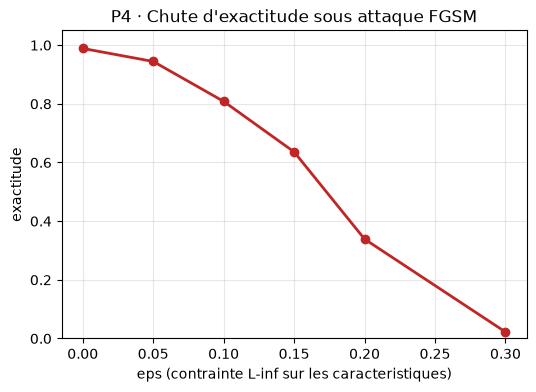

-> un eps de 0.30 sur des scores normalises [0,1] detruit completement le detecteur.


In [11]:
# ---- FGSM white-box attack on our own detector (defensive red-team study) ----
def fgsm(model, X, y, eps):
    # x_adv = x + eps * sign(grad_x BCE)  — untargeted FGSM (Goodfellow 2013).
    return np.clip(X + eps * np.sign(model.grad_input(X, y)), 0.0, 1.0)


def pgd_attack(model, X, y, eps, steps=30, alpha=0.01):
    # Iterative sign steps, kept inside the eps-ball and the feature range.
    Xa = X.copy()
    for _ in range(steps):
        g = model.grad_input(Xa, y)
        Xa = np.clip(Xa + alpha * np.sign(g), X - eps, X + eps)
        Xa = np.clip(Xa, 0.0, 1.0)
    return Xa


eps_grid = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]
fgsm_curve = []
for e in eps_grid:
    Xa = Xte if e == 0 else fgsm(base, Xte, yte, e)
    fgsm_curve.append((e, accuracy(base, Xa, yte)))
    print(f"  eps = {e:.2f}  ->  exactitude sous FGSM = {fgsm_curve[-1][1]:.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot([e for e, _ in fgsm_curve], [a for _, a in fgsm_curve], "o-",
        color="#c12526", lw=2)
ax.set_xlabel("eps (contrainte L-inf sur les caracteristiques)")
ax.set_ylabel("exactitude"); ax.set_title("P4 · Chute d'exactitude sous attaque FGSM")
ax.set_ylim(0.0, 1.05); ax.grid(alpha=0.3)
plt.show()

assert all(fgsm_curve[i + 1][1] < fgsm_curve[i][1] for i in range(len(eps_grid) - 1))
assert 0.55 < fgsm_curve[3][1] < 0.72                    # probed: 0.636 at eps=0.15
assert fgsm_curve[4][1] < 0.40 and fgsm_curve[5][1] < 0.08
print("-> un eps de 0.30 sur des scores normalises [0,1] detruit completement le detecteur.")

In [12]:
# Hand-verify the attack on ONE real test sample: sign vector + L-inf ball
i0 = 0
x0, y0 = Xte[i0], yte[i0]
eps_hand = 0.10
g0 = base.grad_input(x0[None, :], yte[i0:i0 + 1])[0]
sgn0 = np.sign(g0)

assert np.all(np.abs(sgn0) == 1)                         # every coord moves by exactly eps
x0a = np.clip(x0 + eps_hand * sgn0, 0.0, 1.0)
assert np.max(np.abs(x0a - x0)) <= eps_hand + 1e-12      # inside the L-inf eps-ball
assert (x0a >= 0.0).all() and (x0a <= 1.0).all()         # still a legal URL-feature vector
p_clean = float(base.predict_proba(x0[None, :])[0])
p_adv = float(base.predict_proba(x0a[None, :])[0])
print(f"Echantillon {i0}: p(x) = {p_clean:.4f} -> p(x_adv) = {p_adv:.4f}"
      f" (eps = {eps_hand}, L-inf borne verifiee)")

Echantillon 0: p(x) = 0.9996 -> p(x_adv) = 0.9774 (eps = 0.1, L-inf borne verifiee)


### Exercice corrigé

FGSM sur un modèle à **une couche** avec poids connus : le signe du gradient et le point attaqué se calculent à la main, stylo sur papier — puis on compare au calcul vectorisé.

In [13]:
# ---- Exercice P4 : FGSM a la main sur un modele 1-couche a poids connus ----
# Model: p = sigmoid(w.x), w = [0.5, -2.0, 1.0]; BCE gradient wrt x: (p - y) * w
w4 = np.array([0.5, -2.0, 1.0])
x4 = np.array([1.0, 0.5, 1.0])
y4 = 1.0

z4 = float(w4 @ x4)                       # hand: 0.5 - 1.0 + 1.0 = 0.5
assert np.isclose(z4, 0.5)
p4 = 1.0 / (1.0 + np.exp(-z4))            # sigmoid(0.5)
assert np.isclose(p4, 0.6224593312018546)

grad4 = (p4 - y4) * w4                    # (p-1) < 0, so sign(grad) = -sign(w)
assert np.array_equal(np.sign(grad4), np.array([-1.0, 1.0, -1.0]))

eps4 = 0.25
x4a = x4 + eps4 * np.sign(grad4)          # hand: [1-0.25, 0.5+0.25, 1-0.25]
assert np.allclose(x4a, [0.75, 0.75, 0.75])
assert np.isclose(np.max(np.abs(x4a - x4)), eps4)     # L-inf bound: exactly eps
assert np.all(np.abs(x4a - x4) <= eps4 + 1e-12)       # inside the eps-ball

z4a = float(w4 @ x4a)                     # hand: 0.375 - 1.5 + 0.75 = -0.375
assert np.isclose(z4a, -0.375)
p4a = 1.0 / (1.0 + np.exp(-z4a))
assert np.isclose(p4a, 0.40733340004593027)
assert int(p4a >= 0.5) == 0               # DECISION FLIPPED: phishing -> 'legit'
print(f"P4 verifie : p = {p4:.4f} -> p_adv = {p4a:.4f} ; x_adv = {x4a} ;"
      f" ||x_adv - x||_inf = {eps4} (certifie).")

P4 verifie : p = 0.6225 -> p_adv = 0.4073 ; x_adv = [0.75 0.75 0.75] ; ||x_adv - x||_inf = 0.25 (certifie).


## 5 · Défenses : clipping d'entrée, réentraînement adversarial, détection

Trois lignes de défense, chacune **mesurée** :

1. **Clipping d'entrée** — recaler chaque caractéristique dans la plage légale [0,1]. Gratuit, mais ne protège que contre les sorties de plage : un FGSM déjà dans [0,1] n'est pas arrêté.
2. **Réentraînement adversarial** — chaque mini-batch mélange exemples propres et exemples PGD. On observe une **récupération partielle** sous attaque forte, au prix d'un léger sacrifice en exactitude propre (compromis robustesse/exactitude).
3. **Détection par désaccord d'ensemble** — un attaquant optimise contre *un* modèle ; les modèles voisins, initialisés différemment, divergent justement autour de la frontière. Le score d'anomalie = σ des probabilités sur l'ensemble. (Le **marge de confiance** |p−0.5| échoue ici : FGSM fait *déborder* l'exemple de l'autre côté de la frontière, il revient… très confiant.)

**Piège classique :** proclamer « modèle robustifié » en n'évaluant la défense que contre FGSM. Une défense évaluée contre une attaque plus faible que celle de l'adversaire réel est une illusion — on évalue ici sous **PGD-30**, l'attaque standard de la place.

In [14]:
# Defense 1 — input clipping: FGSM samples that leave the legal range [0,1]
g_full = base.grad_input(Xte, yte)
X_adv15 = Xte + 0.15 * np.sign(g_full)          # unclipped attack (as an attacker emits it)
acc_adv_raw = accuracy(base, X_adv15, yte)
acc_adv_clip = accuracy(base, np.clip(X_adv15, 0.0, 1.0), yte)
frac_out = float(np.mean(np.any((X_adv15 < 0) | (X_adv15 > 1), axis=1)))
print(f"Sous FGSM eps=0.15 : exactitude = {acc_adv_raw:.4f}")
print(f"  apres clipping [0,1] des entrees : exactitude = {acc_adv_clip:.4f}"
      f"   ({100 * frac_out:.1f}% des exemples attaquaient hors plage)")
assert 0.05 < frac_out < 0.16                    # probed: 10.6%
assert acc_adv_clip >= acc_adv_raw - 1e-12       # clipping never hurts
print("-> le clipping est un garde-fou d'integrite des donnees, pas une defense complete.")

Sous FGSM eps=0.15 : exactitude = 0.6194
  apres clipping [0,1] des entrees : exactitude = 0.6361   (10.6% des exemples attaquaient hors plage)
-> le clipping est un garde-fou d'integrite des donnees, pas une defense complete.


In [15]:
# Defense 2 — adversarial retraining (PGD examples mixed into every batch).
# Overfit regime (small train set, long training) where standard training collapses
# under PGD and the robust retrain partially recovers.
Xs, ys = Xtr[:240], ytr[:240]
std_def = MLP([8, 32, 1], seed=42, lr=0.03).train(Xs, ys, epochs=600, seed=42)
rob_def = MLP([8, 32, 1], seed=42, lr=0.03).train(Xs, ys, epochs=600, seed=42,
                                                  adv_eps=0.10, adv_steps=3)
acc_std_clean = accuracy(std_def, Xte, yte)
acc_rob_clean = accuracy(rob_def, Xte, yte)
acc_std_pgd = accuracy(std_def, pgd_attack(std_def, Xte, yte, 0.10), yte)
acc_rob_pgd = accuracy(rob_def, pgd_attack(rob_def, Xte, yte, 0.10), yte)
print(f"Standard :  propre {acc_std_clean:.4f}   sous PGD-30 eps=0.10 : {acc_std_pgd:.4f}")
print(f"Adversarial : propre {acc_rob_clean:.4f}   sous PGD-30 eps=0.10 : {acc_rob_pgd:.4f}")
recovery = acc_rob_pgd - acc_std_pgd
print(f"-> recuperation partielle du re-entrainement adversarial : +{recovery:.4f} pts.")

assert acc_std_clean > 0.95 and acc_rob_clean > 0.95
assert acc_rob_pgd - acc_std_pgd > 0.04          # probed: +0.064
assert acc_rob_pgd > 0.75

Standard :  propre 0.9806   sous PGD-30 eps=0.10 : 0.7444
Adversarial : propre 0.9833   sous PGD-30 eps=0.10 : 0.8083
-> recuperation partielle du re-entrainement adversarial : +0.0639 pts.


In [16]:
# Defense 3 — ensemble-disagreement detector: adversarial examples land near a
# decision boundary that *this* model crossed, so differently-seeded models disagree.
ens = [MLP([8, 16, 1], seed=300 + s).train(Xtr, ytr, epochs=150, seed=400 + s)
       for s in range(3)]
P_clean = np.vstack([m.predict_proba(Xte) for m in ens])
P_adv = np.vstack([m.predict_proba(fgsm(base, Xte, yte, 0.10)) for m in ens])
score_clean, score_adv = P_clean.std(0), P_adv.std(0)
det_auc = float(roc_auc_score(np.r_[np.zeros(len(Xte)), np.ones(len(Xte))],
                             np.r_[score_clean, score_adv]))

# The naive margin detector, for comparison (honest negative result):
conf_adv_m = base.predict_proba(fgsm(base, Xte, yte, 0.10))
conf_clean_m = base.predict_proba(Xte)
auc_margin = float(roc_auc_score(np.r_[np.zeros(len(Xte)), np.ones(len(Xte))],
                                 0.5 - np.r_[conf_clean_m, conf_adv_m]))
print(f"Detecteur 'desaccord d'ensemble' : AUC = {det_auc:.4f}")
print(f"Detecteur 'marge de confiance'    : AUC = {auc_margin:.4f}"
      f"  (FGSM overshoot la frontiere -> exemples attaques tres confiants)")
assert det_auc > 0.72                              # probed: 0.803
assert auc_margin < 0.65                           # margin detector useless here (0.53)

Detecteur 'desaccord d'ensemble' : AUC = 0.8034
Detecteur 'marge de confiance'    : AUC = 0.5301  (FGSM overshoot la frontiere -> exemples attaques tres confiants)


### Exercice corrigé

Clipping et seuil du détecteur de marge sur des valeurs données : vérification entièrement calculable à la main.

In [17]:
# ---- Exercice P5 : clipping et detecteur de marge, valeurs a la main ----
# Clipping: every coordinate forced back into the legal feature range [0, 1].
x_raw = np.array([1.4, -0.3, 0.5, 1.0001])
x_clip = np.clip(x_raw, 0.0, 1.0)
assert np.allclose(x_clip, [1.0, 0.0, 0.5, 1.0])
assert (x_clip >= 0.0).all() and (x_clip <= 1.0).all()
assert (x_clip == x_raw)[2]                        # 0.5 already legal -> untouched

# Margin detector: flag when |p - 0.5| < seuil (borderline = suspicious).
conf_adv_h = np.array([0.51, 0.48, 0.62, 0.30])
marges = np.abs(conf_adv_h - 0.5)                  # hand: 0.01, 0.02, 0.12, 0.20
assert np.isclose(marges[0], 0.01) and np.isclose(marges[3], 0.20)
seuil = 0.10
flagges = marges < seuil                            # hand: only 0.51 and 0.48
assert flagges.sum() == 2
assert np.isclose(flagges.mean(), 0.5)
print(f"P5 verifie : clip([1.4, -0.3, 0.5, 1.0001]) = [1, 0, 0.5, 1] ;"
      f" 2/4 exemples marques par le detecteur de marge (seuil {seuil}).")

P5 verifie : clip([1.4, -0.3, 0.5, 1.0001]) = [1, 0, 0.5, 1] ; 2/4 exemples marques par le detecteur de marge (seuil 0.1).


## 6 · Gouvernance, validation & supervision humaine

Un modèle de cybersécurité est un **système à haut risque** (réf. EU AI Act, vue pratique — pas un conseil juridique) : gestion des risques (art. 9), gouvernance des données (art. 10), journalisation (art. 12), **supervision humaine** (art. 14), exactitude/robustesse/cybersécurité (art. 15).

**Checklist de validation avant déploiement** (chaque ligne doit être chiffrée, exécutée ici) :

| # | Contrôle | Preuve exigée |
|---|---|---|
| 1 | Baseline | le modèle bat « toujours légitime » de façon mesurable |
| 2 | Rappel par classe | gap de rappel < seuil (sinon ré-équilibrage, seuils par classe) |
| 3 | Stabilité | écart-type d'exactitude entre graines rapporté |
| 4 | Bruit | courbe de dégradation sous bruit mesurée |
| 5 | Attaque adaptative | courbe exactitude-vs-eps (FGSM) + évaluation PGD |
| 6 | Empoisonnement | chute d'exactitude/rappel à X% d'étiquettes retournées |
| 7 | Dérive | test de dérive + procédure de re-entraînement datée |
| 8 | HITL | bande de confiance basse → file analyste, avec seuil d'alerte |

**Human-in-the-loop par bande de confiance.** Score de confiance = max(p, 1−p). Si la confiance tombe dans la bande [0.35, 0.65], le verdict part en **file d'analyse humaine** au lieu d'être automatiquement appliqué. On mesure la part routée : propre (coût opérationnel) et sous attaque (le HITL absorbe les décisions retournées). Seuil d'alerte : > 10 % routés, ou rappel minoritaire en baisse → gel du déploiement.

Référentiels cités (sans téléchargement) : **MITRE ATLAS** — *Evade AI Model* (AML.T0015), *Poison Training Data* (AML.T0020), *Craft Adversarial Data* (AML.T0043), *AI Model Inference API Access* (AML.T0040) ; **OWASP ML Security Top 10** — *ML01:2023 Input Manipulation Attack*, *ML02:2023 Data Poisoning Attack*, *ML10:2023 Model Poisoning*.

**Piège classique :** déployer « 99 % d'exactitude, feux verts » sans HITL : les 1 % restants sont précisément les cas attaqués, et ils deviennent invisibles.

In [18]:
# Confidence-band HITL routing: share of samples sent to the analyst queue
LOW, HIGH = 0.35, 0.65
conf_clean = base.predict_proba(Xte)
conf_attack = base.predict_proba(fgsm(base, Xte, yte, 0.10))
hitl_clean = float(np.mean((conf_clean >= LOW) & (conf_clean <= HIGH)))
hitl_attack = float(np.mean((conf_attack >= LOW) & (conf_attack <= HIGH)))
print(f"Bande de confiance [{LOW}, {HIGH}] -> part routee vers l'analyste :")
print(f"  trafic propre   : {100 * hitl_clean:.2f}%")
print(f"  sous FGSM 0.10  : {100 * hitl_attack:.2f}%")
print("-> le HITL absorbe les decisions basculees par l'attaque ; alerte si > 10%.")

assert 0 < hitl_clean < 0.04                       # probed: 1.11%
assert hitl_attack > 3 * hitl_clean                # probed: 6.67% vs 1.11%
assert hitl_attack < 0.15                          # operational load still sane

Bande de confiance [0.35, 0.65] -> part routee vers l'analyste :
  trafic propre   : 1.11%
  sous FGSM 0.10  : 6.67%
-> le HITL absorbe les decisions basculees par l'attaque ; alerte si > 10%.


### Exercice corrigé

Routage HITL sur une liste de confiances donnée : la part envoyée en analyse se compte à la main.

In [19]:
# ---- Exercice P6 : routage HITL sur confiance, liste calculee a la main ----
conf6 = np.array([0.51, 0.90, 0.49, 0.50, 0.44, 0.60, 0.95, 0.52])
LOW6, HIGH6 = 0.45, 0.55                            # confidence band around 0.5
# confidence = max(p, 1-p); routing <=> LOW6 <= conf <= HIGH6 <=> |p - 0.5| <= 0.05
routed = np.abs(conf6 - 0.5) <= 0.05                # hand: 0.51, 0.49, 0.50, 0.52
assert np.array_equal(routed, np.array([True, False, True, True,
                                        False, False, False, True]))
assert int(routed.sum()) == 4
assert np.isclose(routed.mean(), 0.5)
alerte = float(routed.mean()) > 0.10                # probed operational alert rule
assert bool(alerte)
print(f"P6 verifie : 4/8 = {routed.mean():.0%} routages analyste -> regle d'alerte (>10%) declenchee.")

P6 verifie : 4/8 = 50% routages analyste -> regle d'alerte (>10%) declenchee.


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| Point | Message clé | Preuve mesurée dans le notebook |
|---|---|---|
| P1 Robustesse & stabilité | Une métrique sans écart-type entre graines ne vaut rien ; certificat L∞ = marge > ε·‖w‖₁ | courbe bruit σ (P1), std inter-graines ≈ 0.002 |
| P2 Biais & dérives | L'exactitude masque l'effondrement du rappel minoritaire ; la dérive se corrige par re-entraînement | gap de rappel ≈ 0.17 ; dérive W4 ≈ 0.84 → re-train ≈ 0.98 |
| P3 Vulnérabilités DL | Opacité ⇒ tester comme une boîte noire ; des étiquettes ciblées aveuglent le détecteur | rappel phishing 0.98 → 0.73 à 30 % d'étiquettes retournées |
| P4 FGSM | Le même gradient qui entraîne attacke : x+ε·sign(∇ₓJ) ; à calibrer sur l'échelle des features | exactitude 0.99 → 0.02 entre ε=0 et ε=0.30 |
| P5 Défenses | Clipping = hygiène ; réentraînement adversarial = récupération partielle (sous PGD !) ; détecteur d'ensemble | +0.06 sous PGD-30 ; AUC détection ≈ 0.80 |
| P6 Gouvernance | Checklist chiffrée, HITL par bande de confiance, référentiels ATLAS / OWASP / EU AI Act | 1 % de routage propre, 7 % sous attaque |

**Exemple intégrateur — la scorecard robustesse.** Une direction de la sécurité n'achète pas « une accuracy » : elle achète un dossier de robustesse. On agrège ici les six mesures du notebook en **une seule table** de gouvernance.

In [20]:
# Integrator: one-page 'scorecard robustesse' aggregating every measurement above.
scorecard = {
    "P1 bruit (sigma=0.30)":     {"exactitude": noise_curve[-1][1], "reference": acc_base},
    "P1 stabilite (std graines)": {"exactitude": float(np.mean(accs)), "reference": seed_std},
    "P2 biais (rappel phish)":   {"exactitude": rec_min, "reference": rec_maj},
    "P2 derive (semaine 4)":      {"exactitude": week_accs[4], "reference": acc_retr},
    "P3 empoisonnement (30%)":    {"exactitude": poison_rows[3][1], "reference": poison_rows[3][2]},
    "P4 FGSM (eps=0.15)":         {"exactitude": fgsm_curve[3][1], "reference": fgsm_curve[0][1]},
}
print("SCORECARD ROBUSTESSE — detecteur phishing (MLP numpy, meme test set)")
print(f"{'Axe de robustesse':32s} {'mesure':>9s} {'ref/contre-epreuve':>19s}")
print("-" * 64)
for ligne, d in scorecard.items():
    print(f"{ligne:32s} {d['exactitude']:9.4f} {d['reference']:19.4f}")

assert len(scorecard) == 6
assert scorecard["P1 bruit (sigma=0.30)"]["exactitude"] == noise_curve[-1][1]
assert scorecard["P4 FGSM (eps=0.15)"]["exactitude"] < scorecard["P1 bruit (sigma=0.30)"]["exactitude"]
assert scorecard["P2 derive (semaine 4)"]["reference"] > scorecard["P2 derive (semaine 4)"]["exactitude"]
print("-> scorecard complete : chaque ligne est reproductible et auditable.")

SCORECARD ROBUSTESSE — detecteur phishing (MLP numpy, meme test set)
Axe de robustesse                   mesure  ref/contre-epreuve
----------------------------------------------------------------
P1 bruit (sigma=0.30)               0.8861              0.9889
P1 stabilite (std graines)          0.9903              0.0020
P2 biais (rappel phish)             0.8235              0.9971
P2 derive (semaine 4)               0.8361              0.9778
P3 empoisonnement (30%)             0.8556              0.7277
P4 FGSM (eps=0.15)                  0.6361              0.9889
-> scorecard complete : chaque ligne est reproductible et auditable.


### Exercice corrigé

À partir de trois scores d'audit (exactitude, robustesse adversariale, gouvernance), calculer la note pondérée de la scorecard — à la main — et décider du feu vert.

In [21]:
# ---- Exercice P7 : note ponderee de la scorecard, calculable a la main ----
scores = {"exactitude": 0.90, "adversarial": 0.60, "gouvernance": 0.80}
weights = {"exactitude": 0.40, "adversarial": 0.30, "gouvernance": 0.30}

note = scores["exactitude"] * weights["exactitude"] \
     + scores["adversarial"] * weights["adversarial"] \
     + scores["gouvernance"] * weights["gouvernance"]
# hand: 0.36 + 0.18 + 0.24 = 0.78
assert np.isclose(note, 0.78)
seuil_departement = 0.80
review_humaine = note < seuil_departement
assert bool(review_humaine)                    # 0.78 < 0.80 -> blocked, human review
assert np.isclose(sum(weights.values()), 1.0)
print(f"P7 verifie : note = 0.36 + 0.18 + 0.24 = {note:.2f} < seuil {seuil_departement}"
      " -> deploiement bloque, revue humaine (HITL).")

P7 verifie : note = 0.36 + 0.18 + 0.24 = 0.78 < seuil 0.8 -> deploiement bloque, revue humaine (HITL).


In [22]:
print("NB 09 — tous les exercices sont vérifiés. ✅")

NB 09 — tous les exercices sont vérifiés. ✅
